# Assignment 1 — Bestselling Books
Yuval Matyovis

## Setup

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## Task 1

### 1.1

In [2]:
my_books = [
    "Harry Potter and the Philosopher's Stone",
    "The Hobbit",
    "1984",
    "Sapiens",
    "The Alchemist",
    "Atomic Habits",
    "The Little Prince",
]

print("First:", my_books[0])
print("Last:", my_books[-1])
print("Length:", len(my_books))

for title in my_books:
    print(f"Book: {title}")

First: Harry Potter and the Philosopher's Stone
Last: The Little Prince
Length: 7
Book: Harry Potter and the Philosopher's Stone
Book: The Hobbit
Book: 1984
Book: Sapiens
Book: The Alchemist
Book: Atomic Habits
Book: The Little Prince


### 1.2

In [3]:
sample_prices = {
    "Harry Potter and the Philosopher's Stone": 12,
    "The Hobbit": 10,
    "1984": 9,
    "Sapiens": 22,
    "The Alchemist": 11,
    "Atomic Habits": 18,
    "The Little Prince": 8,
}

avg_price = sum(sample_prices.values()) / len(sample_prices)
most_expensive = max(sample_prices, key=sample_prices.get)

print(f"Average price: {avg_price:.2f}")
print("Most expensive:", most_expensive)

Average price: 12.86
Most expensive: Sapiens


## Task 2

### 2.1 Load

In [4]:
# local file if it exists, otherwise from my github
LOCAL_PATH = "data/bestsellers.csv"
DATA_URL = "https://raw.githubusercontent.com/YuvalMatyovis/ml-course/main/assignment1/data/bestsellers.csv"

books = pd.read_csv(LOCAL_PATH if os.path.exists(LOCAL_PATH) else DATA_URL)

display(books.head())
print("Shape:", books.shape)
print("Columns:", list(books.columns))

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,"Act Like a Lady, Think Like a Man: What Men Really Think About Love, Relationships, Intimacy, and Commitment",Steve Harvey,4.6,5013,17,2009,Non Fiction
1,Arguing with Idiots: How to Stop Small Minds and Big Government,Glenn Beck,4.6,798,5,2009,Non Fiction
2,"Breaking Dawn (The Twilight Saga, Book 4)",Stephenie Meyer,4.6,9769,13,2009,Fiction
3,Crazy Love: Overwhelmed by a Relentless God,Francis Chan,4.7,1542,14,2009,Non Fiction
4,Dead And Gone: A Sookie Stackhouse Novel (Sookie Stackhouse/True Blood),Charlaine Harris,4.6,1541,4,2009,Fiction


Shape: (700, 7)
Columns: ['Name', 'Author', 'User Rating', 'Reviews', 'Price', 'Year', 'Genre']


### 2.2 Types

In [5]:
display(books.dtypes.to_frame("dtype"))

num_cols = books.select_dtypes(include="number").columns.tolist()
cat_cols = books.select_dtypes(exclude="number").columns.tolist()
print("\nNumeric:", num_cols)
print("Categorical:", cat_cols)

print("\nMissing values:", books.isna().sum().sum())
print("Duplicate rows:", books.duplicated().sum())

,dtype
Name,str
Author,str
User Rating,float64
Reviews,int64
Price,int64
Year,int64
Genre,str



Numeric: ['User Rating', 'Reviews', 'Price', 'Year']
Categorical: ['Name', 'Author', 'Genre']

Missing values: 0
Duplicate rows: 0


### 2.3 Columns
- **Name** – book title
- **Author** – author
- **User Rating** – average rating (1–5)
- **Reviews** – number of reviews (popularity)
- **Price** – price in USD
- **Year** – year it was on the Top-50 list
- **Genre** – Fiction / Non Fiction

A row = book in a specific year, so books can repeat.

### 2.4 Unique values

In [6]:
print("Unique books:", books["Name"].nunique())
print("Unique authors:", books["Author"].nunique())
display(books["Genre"].value_counts().to_frame("rows"))

Unique books: 441
Unique authors: 305


,rows
Genre,
Non Fiction,388
Fiction,312


### 2.5 Cleaning

In [7]:
# books = all rows (by year), books_unique = one row per book (books & authors)
for col in ["Name", "Author", "Genre"]:
    books[col] = books[col].str.strip()

# is Reviews the same for a book in every year?
per_book = books.groupby(["Name", "Author"]).agg(years=("Year", "size"), review_values=("Reviews", "nunique"))
repeated = per_book[per_book["years"] > 1]
print("Books on the list more than once:", len(repeated))
print("Same Reviews every year:", (repeated["review_values"] == 1).sum())

# price 0 is probably a free/promo edition -> NaN for price analysis
print("\nRows with Price = 0:", (books["Price"] == 0).sum())
books["Price_clean"] = books["Price"].replace(0, np.nan)

# one row per book, first year on the list
books_unique = books.sort_values("Year").drop_duplicates(["Name", "Author"], keep="first").reset_index(drop=True)
print("\nbooks:", books.shape)
print("books_unique:", books_unique.shape)

Books on the list more than once: 122
Same Reviews every year: 97

Rows with Price = 0: 12

books: (700, 8)
books_unique: (440, 8)


## Task 3

In [8]:
high_rated = books_unique[books_unique["User Rating"] >= 4.8]
print("Rating >= 4.8:", len(high_rated))

many_reviews = books_unique[books_unique["Reviews"] > 50000]
print("Reviews > 50,000:", len(many_reviews))

cheap_books = books_unique[books_unique["Price_clean"] <= 10]
print("Price <= 10:", len(cheap_books))
display(cheap_books.head())

Rating >= 4.8: 148
Reviews > 50,000: 28
Price <= 10: 180


,Name,Author,User Rating,Reviews,Price,Year,Genre,Price_clean
1,Arguing with Idiots: How to Stop Small Minds and Big Government,Glenn Beck,4.6,798,5,2009,Non Fiction,5.0
4,Dead And Gone: A Sookie Stackhouse Novel (Sookie Stackhouse/True Blood),Charlaine Harris,4.6,1541,4,2009,Fiction,4.0
6,"Divine Soul Mind Body Healing and Transmission System: The Divine Way to Heal You, Humanity, Mother Earth, and All…",Zhi Gang Sha,4.6,37,6,2009,Non Fiction,6.0
8,Eat This Not That! Supermarket Survival Guide: The No-Diet Weight Loss Solution,David Zinczenko,4.5,720,1,2009,Non Fiction,1.0
10,Eclipse (Twilight Sagas),Stephenie Meyer,4.7,5505,7,2009,Fiction,7.0


### 3.4

In [9]:
low_rated = books_unique[books_unique["User Rating"] < 4.0]

print(f"Rating >= 4.8: {len(high_rated)} books, avg reviews = {high_rated['Reviews'].mean():,.0f}")
print(f"Rating < 4.0:  {len(low_rated)} books, avg reviews = {low_rated['Reviews'].mean():,.0f}")

Rating >= 4.8: 148 books, avg reviews = 15,435
Rating < 4.0:  5 books, avg reviews = 22,355


## Task 4

### 4.1 By genre

In [10]:
genre_stats = books_unique.groupby("Genre").agg(
    avg_rating=("User Rating", "mean"),
    avg_price=("Price_clean", "mean"),
    avg_reviews=("Reviews", "mean"),
).round(2)
genre_stats

,avg_rating,avg_price,avg_reviews
Genre,,,
Fiction,4.63,12.46,19222.00
Non Fiction,4.62,13.83,11537.86


### 4.2 By year and genre

In [11]:
year_genre_stats = books.groupby(["Year", "Genre"]).agg(
    avg_rating=("User Rating", "mean"),
    avg_price=("Price_clean", "mean"),
).round(2)
year_genre_stats.head(10)

avg_rating  avg_price
Year Genre                             
2009 Fiction            4.59      15.58
     Non Fiction        4.58      15.23
2010 Fiction            4.62      10.21
     Non Fiction        4.52      16.00
2011 Fiction            4.62      12.20
     Non Fiction        4.51      17.62
2012 Fiction            4.50      12.29
     Non Fiction        4.56      17.48
2013 Fiction            4.55      11.68
     Non Fiction        4.56      18.19

### 4.3 Top authors

In [12]:
top_by_books = books_unique["Author"].value_counts().head(5)
top_by_reviews = books_unique.groupby("Author")["Reviews"].sum().sort_values(ascending=False).head(5)

print("By number of books:")
display(top_by_books.to_frame("books"))
print("By total reviews:")
display(top_by_reviews.to_frame("reviews"))

# counting rows instead - same book counted every year
print("By rows:")
display(books["Author"].value_counts().head(5).to_frame("rows"))

By number of books:


,books
Author,
Jeff Kinney,14
Rick Riordan,10
Stephenie Meyer,8
Dav Pilkey,8
Suzanne Collins,6


By total reviews:


,reviews
Author,
Colleen Hoover,255531
Suzanne Collins,174293
Kristin Hannah,146098
Matt Haig,144313
E L James,130746


By rows:


,rows
Author,
Jeff Kinney,14
Gary Chapman,14
Suzanne Collins,12
American Psychological Association,11
Rick Riordan,11


### 4.4 reviews_per_year

In [13]:
# data goes to 2022, so 2020 - Year breaks -> use last year + 1
CURRENT_YEAR = books["Year"].max() + 1
years_listed = (CURRENT_YEAR - books_unique["Year"]).clip(lower=1)  # no division by 0
books_unique["reviews_per_year"] = books_unique["Reviews"] / years_listed

books_unique.sort_values("reviews_per_year", ascending=False)[
    ["Name", "Author", "Year", "Reviews", "reviews_per_year"]
].head(10).round(0)

,Name,Author,Year,Reviews,reviews_per_year
409,The Midnight Library: A Novel,Matt Haig,2021,144313,72156.0
439,Verity,Colleen Hoover,2022,71826,71826.0
429,Reminders of Him: A Novel,Colleen Hoover,2022,56049,56049.0
406,The Four Winds: A Novel,Kristin Hannah,2021,96810,48405.0
351,A Promised Land,Barack Obama,2020,121109,40370.0
408,The Last Thing He Told Me: A Novel,Laura Dave,2021,77903,38952.0
434,The Lincoln Highway: A Novel,Amor Towles,2022,38675,38675.0
398,It Ends with Us: A Novel (1),Colleen Hoover,2021,76135,38068.0
405,"The Alchemist, 25th Anniversary: A Fable About Following Your Dream",Paulo Coelho,2021,71252,35626.0
402,Rich Dad Poor Dad: What the Rich Teach Their Kids About Money That the Poor and Middle Class Do Not!,Robert T. Kiyosaki,2021,71078,35539.0


## Task 5

### 5.1 Rating

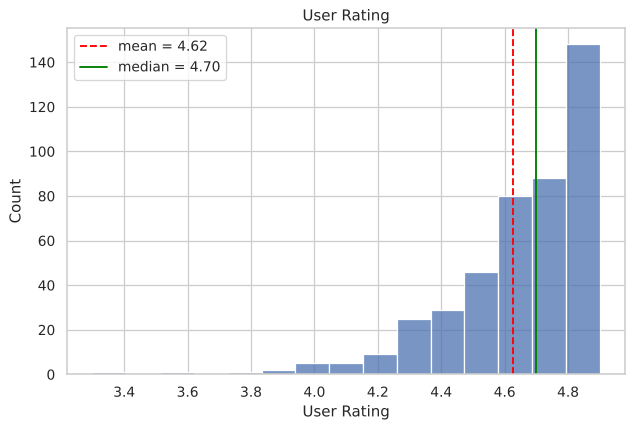

In [14]:
mean_r = books_unique["User Rating"].mean()
median_r = books_unique["User Rating"].median()

sns.histplot(books_unique["User Rating"], bins=15)
plt.axvline(mean_r, color="red", linestyle="--", label=f"mean = {mean_r:.2f}")
plt.axvline(median_r, color="green", label=f"median = {median_r:.2f}")
plt.title("User Rating")
plt.legend()
plt.show()

### 5.2 Price by genre

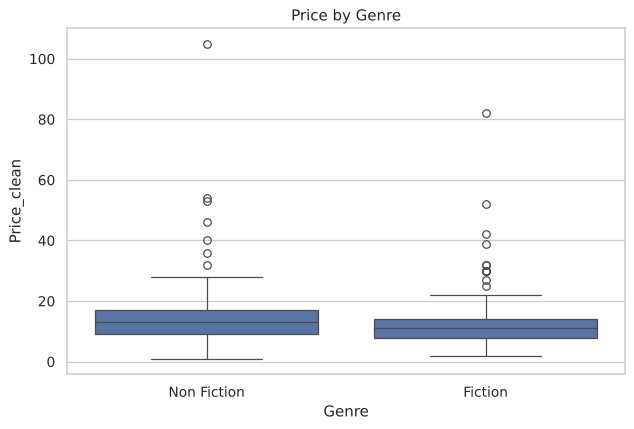

,count,mean,std,min,25%,50%,75%,max
Genre,,,,,,,,
Fiction,196.0,12.5,8.6,2.0,7.8,11.0,14.0,82.0
Non Fiction,235.0,13.8,9.6,1.0,9.0,13.0,17.0,105.0


In [15]:
sns.boxplot(data=books_unique, x="Genre", y="Price_clean")
plt.title("Price by Genre")
plt.show()

display(books_unique.groupby("Genre")["Price_clean"].describe().round(1))

**Note:** Non Fiction is a bit more expensive (median 13 vs 11). The very expensive ones are professional manuals (DSM-5 $105, APA manual) and box sets (Twilight collection $82).

### 5.3 Reviews vs rating

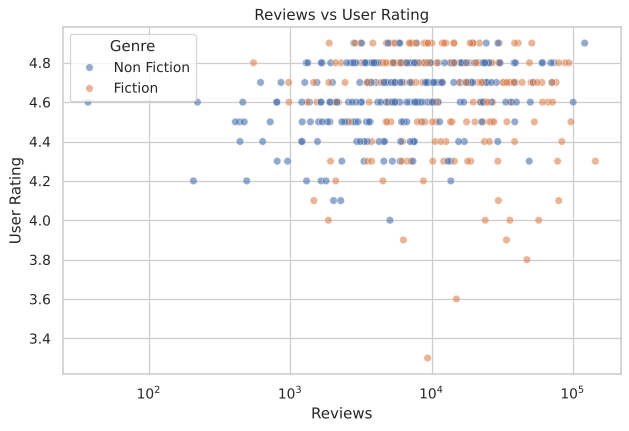

In [16]:
sns.scatterplot(data=books_unique, x="Reviews", y="User Rating", hue="Genre", alpha=0.6)
plt.xscale("log")  # reviews are very skewed
plt.title("Reviews vs User Rating")
plt.show()

### 5.4 Rating per year

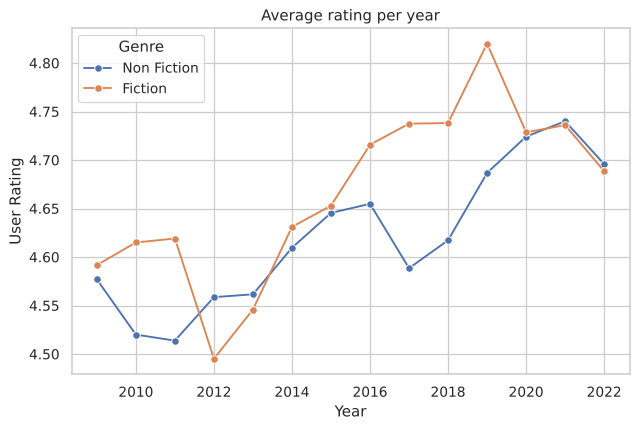

In [17]:
sns.lineplot(data=books, x="Year", y="User Rating", hue="Genre", marker="o", errorbar=None)
plt.title("Average rating per year")
plt.show()

### 5.5 Price category

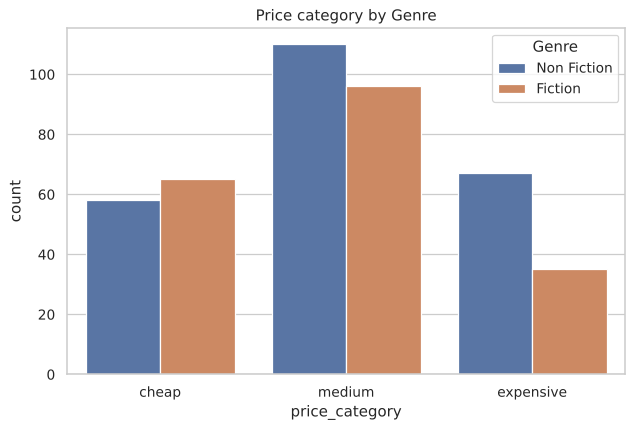

Genre,Fiction,Non Fiction
price_category,,
cheap,65,58
medium,96,110
expensive,35,67


In [18]:
# thresholds = 25% / 75% quantiles of price
books_unique["price_category"] = pd.cut(
    books_unique["Price_clean"],
    bins=[0, 8, 16, np.inf],
    labels=["cheap", "medium", "expensive"],
)

sns.countplot(data=books_unique, x="price_category", hue="Genre")
plt.title("Price category by Genre")
plt.show()

display(pd.crosstab(books_unique["price_category"], books_unique["Genre"]))

## Task 6

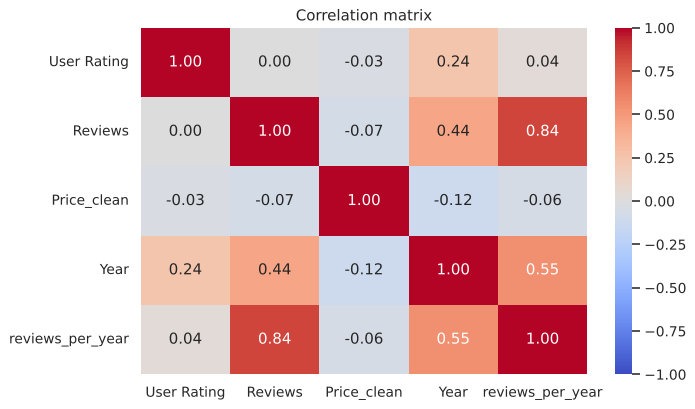

In [19]:
corr_cols = ["User Rating", "Reviews", "Price_clean", "Year", "reviews_per_year"]
corr = books_unique[corr_cols].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

### 6.3 Blockbusters

In [20]:
# rule: rating >= 4.8 and reviews in the top 25%
reviews_q75 = books_unique["Reviews"].quantile(0.75)
print(f"Reviews threshold: {reviews_q75:,.0f}")

books_unique["is_blockbuster"] = (books_unique["User Rating"] >= 4.8) & (books_unique["Reviews"] >= reviews_q75)
blockbusters = books_unique[books_unique["is_blockbuster"]]

print(f"Blockbusters: {len(blockbusters)} ({len(blockbusters) / len(books_unique):.1%})")
print("By year:", blockbusters["Year"].value_counts().sort_index().to_dict())
display(blockbusters["Author"].value_counts().head(5).to_frame("blockbusters"))
display(blockbusters["Genre"].value_counts().to_frame("blockbusters"))
display(books_unique.groupby("is_blockbuster")["Price_clean"].median().to_frame("median price"))

Reviews threshold: 19,019
Blockbusters: 36 (8.2%)
By year: {2010: 1, 2011: 1, 2012: 1, 2013: 3, 2014: 1, 2015: 2, 2016: 1, 2018: 3, 2019: 1, 2020: 17, 2021: 4, 2022: 1}


,blockbusters
Author,
School Zone,2
Adam Wallace,2
Laura Hillenbrand,1
Sarah Young,1
Dr. Seuss,1


,blockbusters
Genre,
Non Fiction,19
Fiction,17


,median price
is_blockbuster,
False,12.0
True,9.0


## Task 7

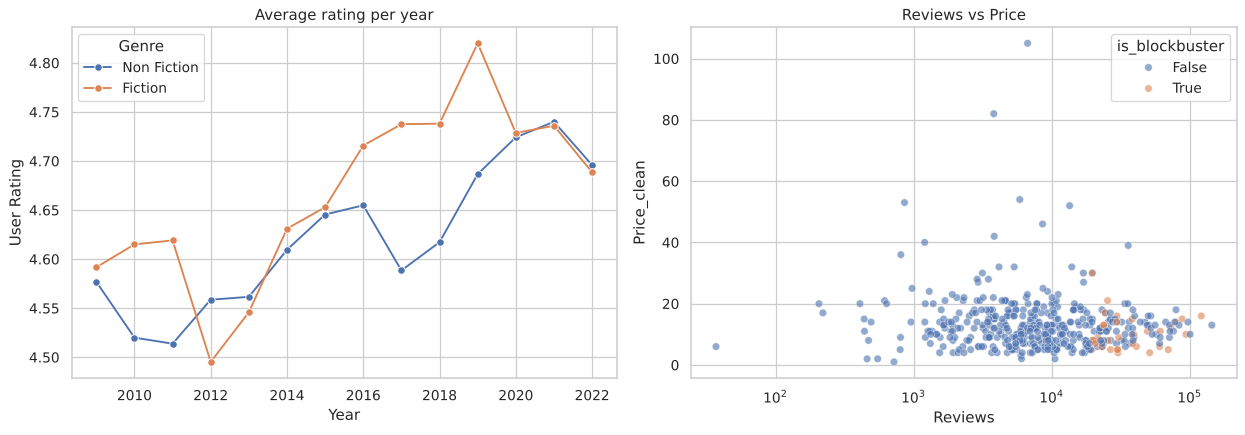

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(data=books, x="Year", y="User Rating", hue="Genre", marker="o", errorbar=None, ax=axes[0])
axes[0].set_title("Average rating per year")

sns.scatterplot(data=books_unique, x="Reviews", y="Price_clean", hue="is_blockbuster", alpha=0.6, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title("Reviews vs Price")

plt.tight_layout()
plt.show()

### Conclusion
Almost every bestseller is rated 4.5–4.9, so rating is the minimum to get on the list but doesn't separate the books — the number of reviews varies much more and shows popularity better. Rating and reviews aren't correlated at all; controversial books even get more reviews. Ratings also rise over the years, which looks like rating inflation.

Non Fiction is a bit more expensive than Fiction (avg ~$13.8 vs ~$12.5), mainly because of professional manuals and guides, but the gap is small.

No author or genre dominates the blockbusters — they come from many different authors. Many are recent and cheap, especially kids' books from 2020 (COVID).

**What I'd tell a publisher:** a good rating is a must, but what bestsellers really have in common is getting a lot of reviews fast, an affordable price (~$10), and a wide audience — e.g. kids and families.